<a href="https://colab.research.google.com/github/krueg-lars-web/DataSciene/blob/main/colab/exercise_04/evaluation-metrics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Evaluation Metrics

## Regression vs. Classification

Two very simple datasets are plotted below.
Let's say we have to predict `y` from `x` in each of them.

> <font color="#e8710a">**📝 Tasks**</font>
>
> 1. One of the datasets defines a classification problem and the other one defines a regression problem. Which is which?
> 2. Explain your answer!

**✏️ Your answer**

1. Dataset A -> Regression
  
   Dataset B -> Klassifikation


2. Dataset A -> Die Punkte folgen einer gedachten Linie, Kontinuierliche Achsen
  
   Dataset B -> Die Punkte sind in 3 Klare Klassen einteilbar und somit Klassifizierbar

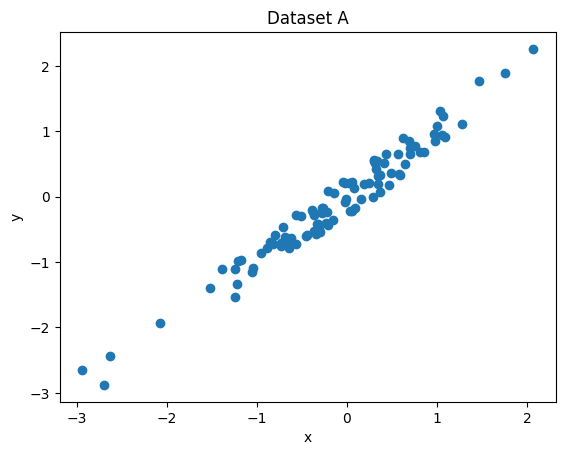

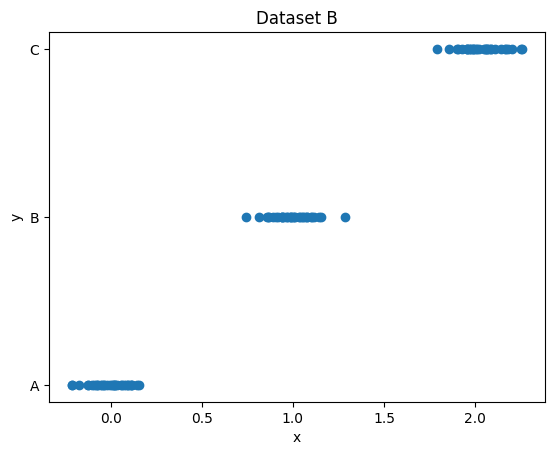

In [1]:
import numpy as np
import matplotlib.pyplot as plt

dataset_a = np.random.normal(0.0, 1.0, 100)

plt.scatter(dataset_a, dataset_a + np.random.uniform(-0.3, 0.3, 100))
plt.xlabel("x")
plt.ylabel("y")
plt.title("Dataset A")
plt.show()

dataset_b = np.concat([np.random.normal(i, 0.1, 33) for i in range(3)])

plt.scatter(dataset_b, np.concat([[value]*33 for value in ["A", "B", "C"]]))
plt.title("Dataset B")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

### Regression

#### MAE vs MSE

Let $y_i$ be the actual value and $\hat{y}_i$ be the predicted value, then:

$$MAE = \frac{1}{n} \sum_i |y_i - \hat{y}_i|$$

and

$$MSE = \frac{1}{n} \sum_i (y_i - \hat{y}_i)^2.$$

The MAE and MSE are applied on the example data below to evaluate a mean predictor model.

> <font color="#e8710a">**📝 Tasks**</font>
>
> 3. What pros/cons do you see in this example for the MAE and the MSE respectively?

**✏️ Your answer**

3. Die Gewichtung der Ausreißer unterscheidet sich bei den jeweiligen Methoden. Bei dem MAE sind die Fehler linear Gewichtet, beim MSE quadratisch, wodurch die Gewichtung eines einzelfehlers strärker ausfällt. Für Modellierungen ist jedoch der MSE besser da er eine Kurve bildet und keinen Winkel am Nullpunkt hat.

mean = 1.8
Mean Predictor MAE = 1.4400
Mean Predictor MSE = 5.7600


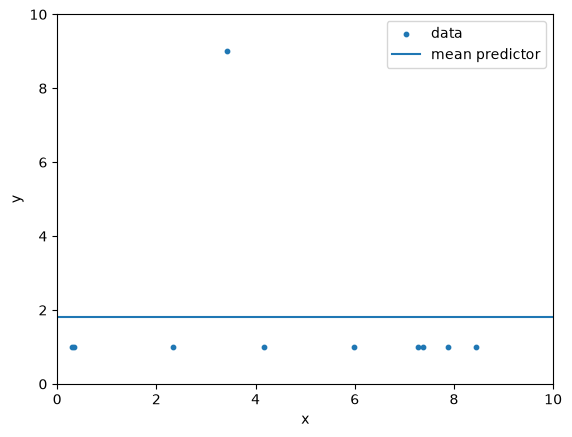

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae_vs_mse_X = np.random.uniform(0, 10, 10)
mae_vs_mse_dataset = np.array([[x, 1] for x in mae_vs_mse_X])
mae_vs_mse_dataset[-1, 1] = 9

mean_predictor = np.mean(mae_vs_mse_dataset[:, 1])

print("mean =", mean_predictor)

mae = mean_absolute_error(mae_vs_mse_dataset[:, 1], [mean_predictor]*10)
mse = mean_squared_error(mae_vs_mse_dataset[:, 1], [mean_predictor]*10)

print(f"Mean Predictor MAE = {mae:.4f}")
print(f"Mean Predictor MSE = {mse:.4f}")

plt.scatter(mae_vs_mse_dataset[:, 0], mae_vs_mse_dataset[:, 1], s=10)
plt.axhline(mean_predictor)

plt.xlim([0, 10])
plt.ylim([0, 10])

plt.xlabel("x")
plt.ylabel("y")
plt.legend(["data", "mean predictor"])

plt.show()

#### $R^2$

Let $y_i$ be the actual value, $\hat{y}_i$ the predicted value and $\bar{y} = \frac{1}{n} \sum_i y_i$ the mean of all actual values. Then,

$$R^2 = 1 - \frac{\sum_i (y_i - \hat{y}_i)^2}{\sum_j (y_j - \bar{y})^2}.$$

> <font color="#e8710a">**📝 Tasks**</font>
>
> 4. What is the $R^2$ of the mean predictor?
> 5. What is the best possible $R^2$ a model could get?
> 6. What is the worst possible $R^2$ a model could get?
> 7. Bonus: How is $R^2$ related to the variance in the data? (**Hint:** Have a close look at the denominator (bottom of the fraction).)

**✏️ Your answer**

4. Durchschnittlicher Fehler des Modells $$ → 0 $$

5. $$
→ 1
$$


6. $$
    → \infty
   $$
   

7. Anteil der Varianz der durch das Model erklärt wird (unter dem Bruchstrich)


### Classification

#### Confusion Matrix

> <font color="#e8710a">**📝 Tasks**</font>
>
> 8. Fill in the cell names in the cells marked with an `x` in the following confusion matrix of a binary classification problem.
> 9. Briefly state what each of the four non-bold cells represent.
> 10. Turn the following multi-class confusion matrix into a binary classification confusion matrix for `C2` as the positive class.
>
> |        | C1 | C2 | C3 | C4 |
> |--------|----|----|----|----|
> | **C1** | 1  | 2  | 3  | 4  |
> | **C2** | 5  | 6  | 7  | 8  |
> | **C3** | 9  | 10 | 11 | 12 |
> | **C4** | 13 | 14 | 15 | 16 |

**✏️ Your answer**

8.

|       | Vorhergesagt positv | Vorhergesagt negativ |
|-------|---|---|
| **tatsächlich positiv** | richtig positive | falsch negativ |
| **tatsächlich negativ** | falsch positiv | richtig negativ |

9.
10.

|       | Vorhergesagt C2 Positiv | Vorhergesagt C2 Negativ |
|-------|---|---|
| **tatsächlich C2 Positiv** | 6 | 5, 7, 8 = 20 |
| **tatsächlich C2 Negativ** | 2, 10, 14 = 26| 1, 9, 13, 3, 11, 15, 4, 12, 16 = 84 |

#### Properties of precision and recall
What unwanted (trivial) strategies could a classifier predicting the class `0` or `1` employ to...

> <font color="#e8710a">**📝 Tasks**</font>
>
> 11. always get a *precision* of `1`?
> 12. always get a *recall* of `1`?

**✏️ Your answer**

$$
  Precision=\frac{TP}{TP+FP}
$$
$$
  Recall=\frac{TP}{TP+FN}
$$

11. nur als Klasse 1 klassifizieren, wenn auch wirklich wahr pos. --> es wird niemand als pos. erkannt, der es nicht ist. somit keine falsch pos. mehr
--> opt. nur Klasse 0 voraussagen dann gibt es auch keine falsch. pos.

12. einfach alle als Klasse 1 klassifizieren --> es wird niemand fälschlicherweise nicht erkannt. somit keine falsch neg. mehr

#### Choosing between precision and recall

> <font color="#e8710a">**📝 Tasks**</font>
>
> 13. In what settings is precision more important than recall and in which applications is recall more important than precision? **Hint:** As an example, think of a spam filter which has to differentiate between spam and important mails from your boss.

**✏️ Your answer**

13. hier besser eine hohe präzision zu haben da somit die falsch positiven im normalen Postfach landen und somit wichtige E-mails nicht untergehen

#### Combine precision and recall

> <font color="#e8710a">**📝 Tasks**</font>
>
> 14. What is a measure that combines precision and recall?
> 15. Define it.
> 16. Why do we use the harmonic rather than the arithmetic mean?

**✏️ Your answer**

14.
15.
16.

#### ROC AUC

ROC AUC is for binary classifiers that predict class scores instead of class membership.

> <font color="#e8710a">**📝 Tasks**</font>
>
> 17. How can class scores be converted to predictions of class membership?
> 18. Assume you have an evaluation set of $n$ data points and a unique class score prediction for each of them from your model. How many unique sets of class membership predictions can be defined using the method from your answer to the previous question?
> 19. Define the axes of ROC space based on the values in a confusion matrix.

**✏️ Your answer**

17.
18.
19. $$x = $$
    $$y = $$